In [2]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from astropy.io import fits
import os

In [9]:
#seperate data in filters into dictionary
dir = r"C:\Users\jw141\Desktop\astrolab_observations\data\m27_new"
filters = ["black","Red","Blue","Green"]

data = {}
for filter in filters:
    data[filter] = []

files = os.listdir(dir)
for file in files:
    for filter in filters:
        if (filter in file) and ("calibrated" in file):
            data[filter].append(fits.open(dir + r"\\" + file))
            break



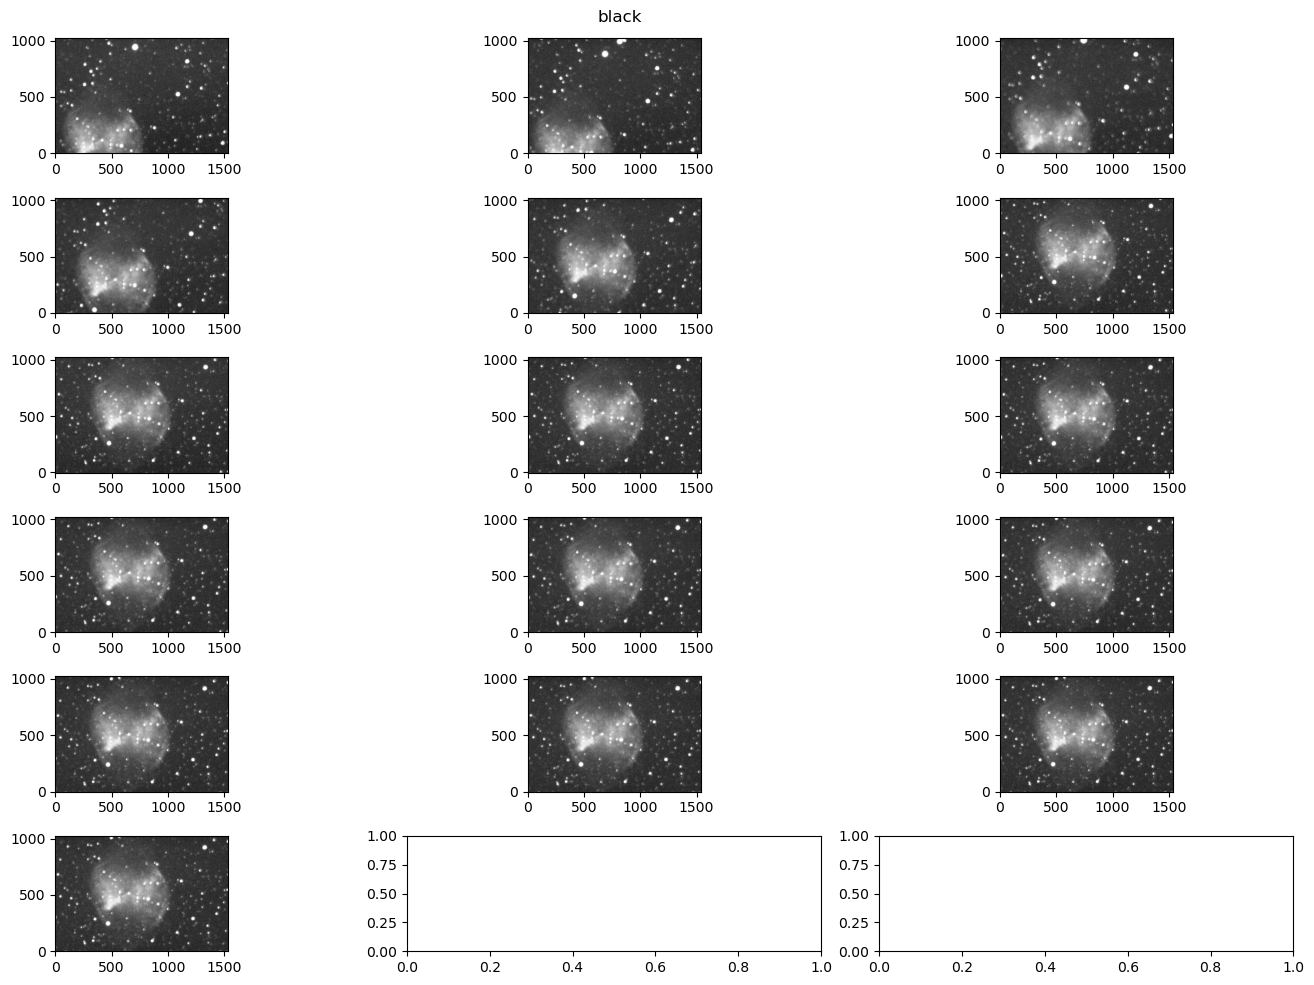

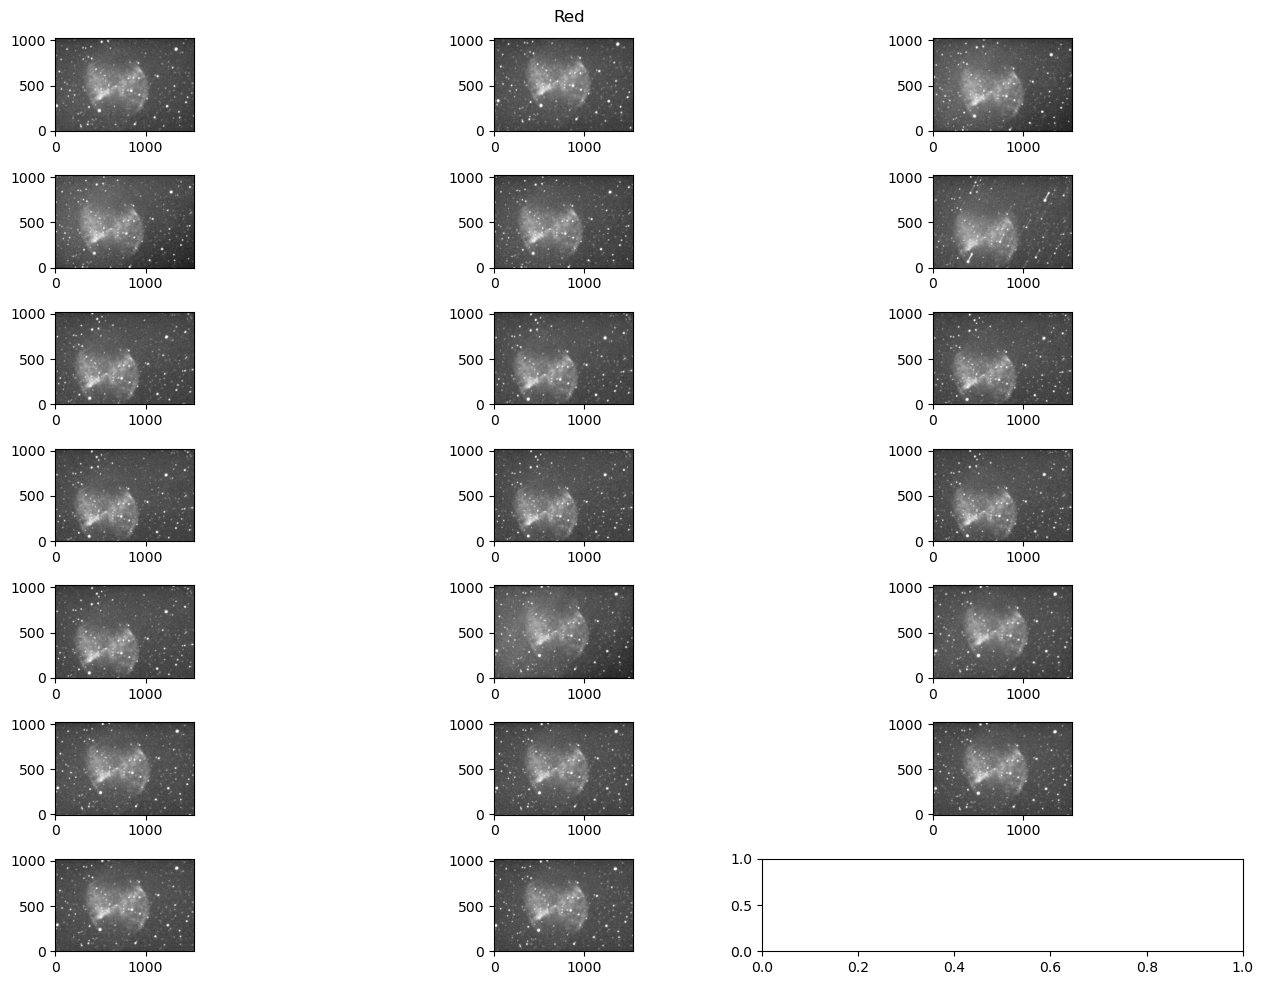

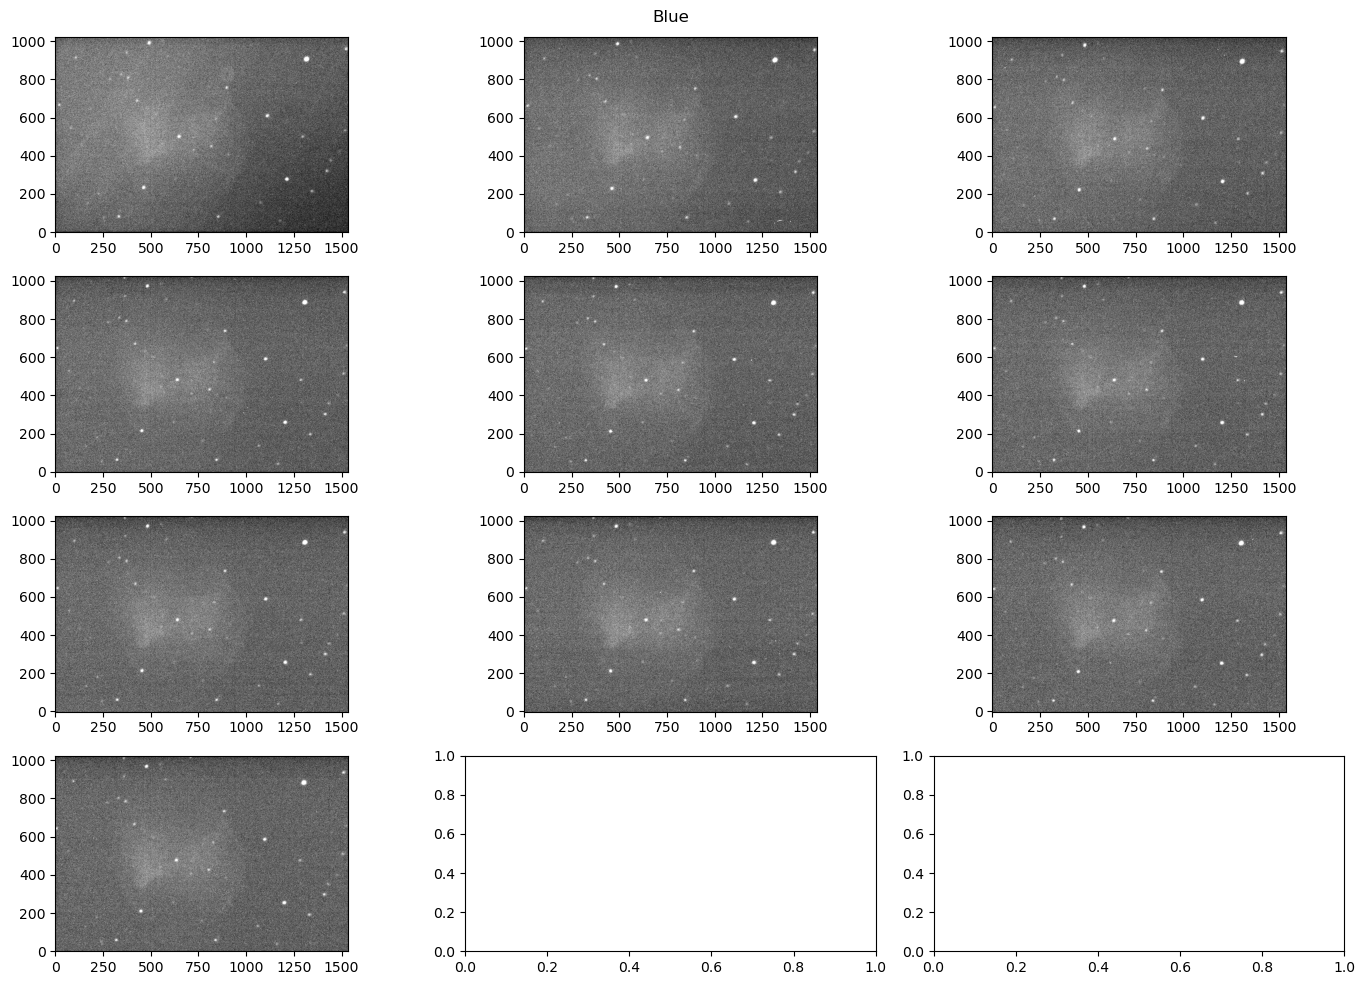

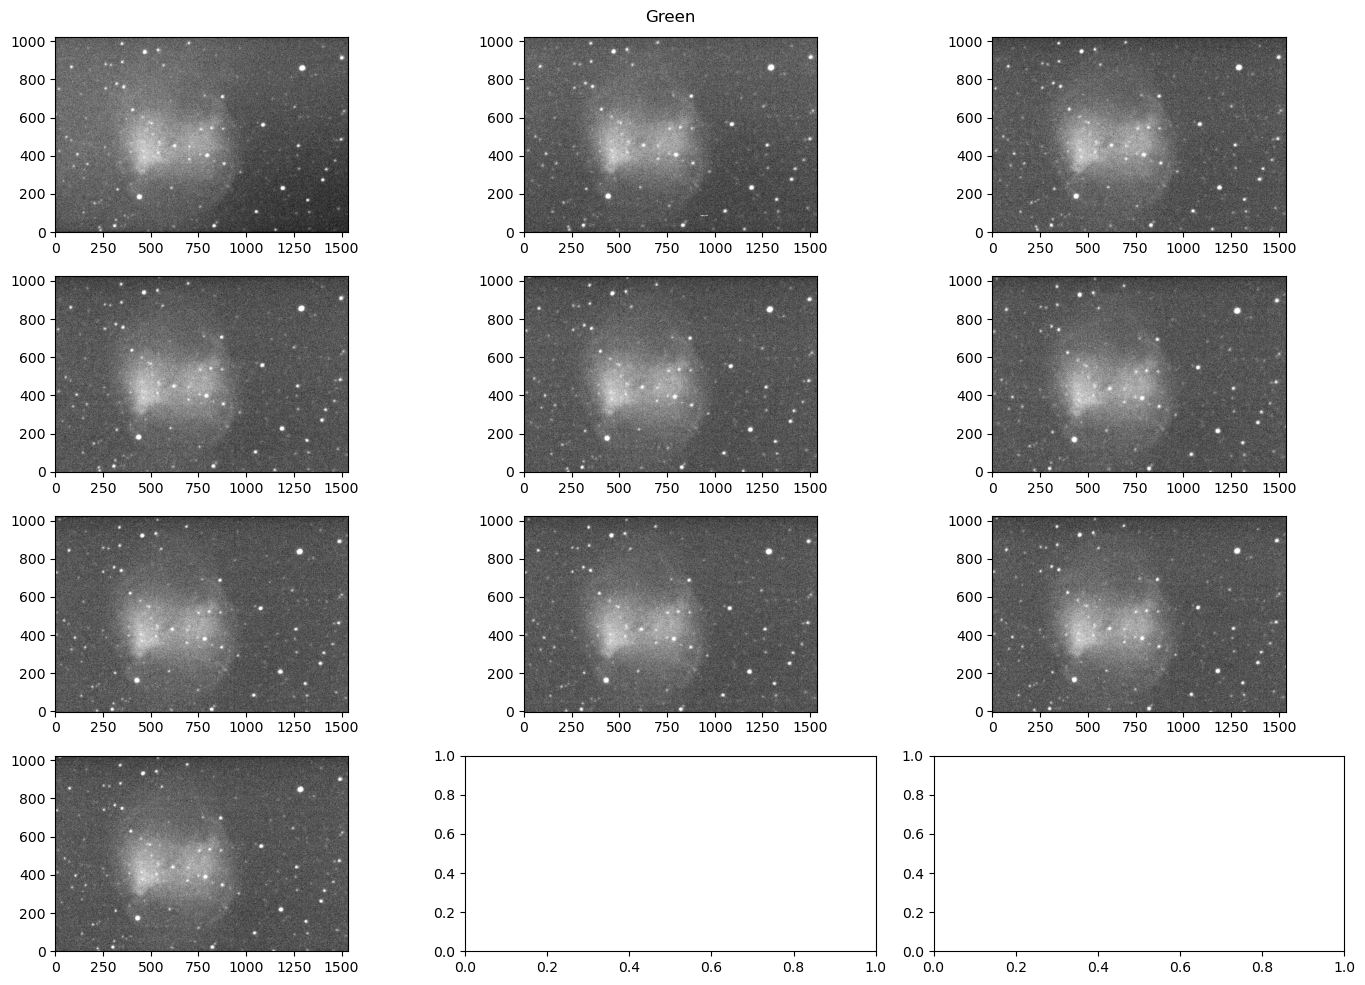

In [15]:
for filter in filters:
    l = len(data[filter]) / 3
    if type(l) == float:
        l = int(l) + 1 
    fig,axs = plt.subplots(l,3,figsize = (14,10))
    for i in range(len(data[filter])):
        m = int(i/3)
        n = i - 3* int(i/3)
        image = data[filter][i][0].data
        lo,up = np.percentile(image,5),np.percentile(image,99)
        axs[m][n].imshow(image,cmap='gray',clim=(lo,up),origin="lower")
    fig.suptitle(filter)
    fig.tight_layout()
    plt.show()